# 4. Match outcomes: does xT add anything beyond xG?

**Questions**
1. Given a match's underlying numbers, but not its goals, how well can we tell who won?
2. Does ball progression (xT, box entries, final-third entries) add information beyond chance quality (npxG, shots)?
3. How much of a team's goal tally in a single match do these metrics explain?

These are **explanatory, post-match models**: features and result come from the same 90 minutes. They measure how much the underlying numbers tell us about the result. They are not pre-match forecasts.

**Setup.** Each match becomes **one row from the home team's point of view**, with every feature expressed as home minus away. The team-match table has two mirrored rows per match; splitting those rows randomly would put one side of a match in training and its mirror image in testing, so the test set wouldn't be independent. Using one row per match avoids that.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.metrics import ConfusionMatrixDisplay
from sklearn.model_selection import (GridSearchCV, GroupKFold, RepeatedStratifiedKFold, StratifiedKFold,
                                     cross_val_predict, cross_validate)
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier, plot_tree

from epl_xt import config
from epl_xt.plotting import MUTED, SEQUENTIAL, SERIES, SURFACE, TEXT_SECONDARY, apply_style, save

apply_style()
pd.set_option("display.precision", 3)
RANDOM_STATE = 42

team_match = pd.read_parquet(config.TEAM_MATCH_TABLE)
home = team_match[team_match["is_home"]].reset_index(drop=True)

DIFF_METRICS = ["npxg", "shots", "xt", "box_entries", "final_third_entries", "passes"]
for m in DIFF_METRICS:
    home[f"{m}_diff"] = home[m] - home[f"{m}_against"]

print(f"{len(home)} matches")
home["result"].value_counts(normalize=True).rename("share of matches (home perspective)")

380 matches


result
W    0.413
L    0.305
D    0.282
Name: share of matches (home perspective), dtype: float64

In [2]:
FEATURE_SETS = {
    "Chance quality (npxG, shots)": ["npxg_diff", "shots_diff"],
    "Progression (xT, entries, passes)": ["xt_diff", "box_entries_diff", "final_third_entries_diff", "passes_diff"],
    "All six": [f"{m}_diff" for m in DIFF_METRICS],
}
home[[f"{m}_diff" for m in DIFF_METRICS]].describe().T[["mean", "std", "min", "max"]]

,mean,std,min,max
npxg_diff,0.229,1.013,-3.025,3.419
shots_diff,3.005,8.147,-21.000,34.000
xt_diff,0.201,0.673,-1.461,2.247
box_entries_diff,3.055,10.319,-30.000,37.000
final_third_entries_diff,6.918,26.950,-82.000,86.000
passes_diff,33.603,194.592,-507.000,508.000


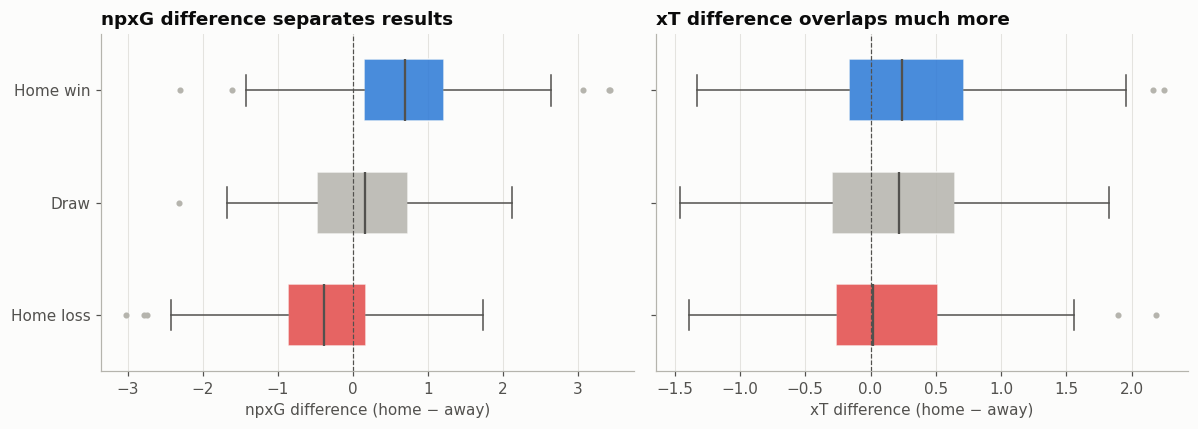

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
order = ["L", "D", "W"]
names = {"L": "Home loss", "D": "Draw", "W": "Home win"}
for ax, col, label in [(axes[0], "npxg_diff", "npxG difference (home − away)"),
                       (axes[1], "xt_diff", "xT difference (home − away)")]:
    data = [home.loc[home["result"] == r, col] for r in order]
    parts = ax.boxplot(data, vert=False, widths=0.55, patch_artist=True,
                       medianprops={"color": TEXT_SECONDARY, "lw": 1.5},
                       whiskerprops={"color": TEXT_SECONDARY}, capprops={"color": TEXT_SECONDARY},
                       flierprops={"marker": "o", "markersize": 3, "markerfacecolor": MUTED, "markeredgecolor": MUTED})
    for patch, color in zip(parts["boxes"], [SERIES[7], MUTED, SERIES[0]]):
        patch.set_facecolor(color)
        patch.set_alpha(0.85)
        patch.set_edgecolor(SURFACE)
    ax.set_yticks([1, 2, 3], [names[r] for r in order])
    ax.axvline(0, color=TEXT_SECONDARY, lw=0.8, ls="--")
    ax.set_xlabel(label)
    ax.grid(axis="y", visible=False)
axes[0].set_title("npxG difference separates results")
axes[1].set_title("xT difference overlaps much more")
fig.tight_layout()
save(fig, "match_result_distributions")
plt.show()

## Q1–2. Classifying the result (home win / draw / home loss)

Three model families are fitted, each on the three feature sets:

* **Multinomial logistic regression**: a linear, well-calibrated baseline.
* **k-nearest neighbours**: *k* and weighting tuned by inner CV.
* **Decision tree**: depth and leaf size tuned by inner CV.

Performance is estimated by **nested cross-validation**: 5-fold stratified outer CV repeated 3 times, with hyperparameters tuned only on each outer training fold. The baseline always predicts the most common result (home win).

In [4]:
y = home["result"]
outer = RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=RANDOM_STATE)
inner = StratifiedKFold(5, shuffle=True, random_state=RANDOM_STATE + 1)

classifiers = {
    "Majority class": DummyClassifier(strategy="most_frequent"),
    "Logistic regression": make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000)),
    "KNN": GridSearchCV(make_pipeline(StandardScaler(), KNeighborsClassifier()),
                        {"kneighborsclassifier__n_neighbors": range(5, 76, 10),
                         "kneighborsclassifier__weights": ["uniform", "distance"]}, cv=inner),
    "Decision tree": GridSearchCV(DecisionTreeClassifier(random_state=RANDOM_STATE),
                                  {"max_depth": range(1, 7), "min_samples_leaf": [5, 15, 30]}, cv=inner),
}

rows = []
for model_name, model in classifiers.items():
    for set_name, cols in FEATURE_SETS.items():
        cv = cross_validate(model, home[cols], y, cv=outer, scoring=["accuracy", "f1_macro"])
        rows.append({"model": model_name, "features": set_name,
                     "accuracy": cv["test_accuracy"].mean(), "accuracy_sd": cv["test_accuracy"].std(),
                     "macro_f1": cv["test_f1_macro"].mean()})
clf_results = pd.DataFrame(rows)
clf_results.pivot(index="model", columns="features", values="accuracy").loc[list(classifiers)]

features,All six,"Chance quality (npxG, shots)","Progression (xT, entries, passes)"
model,,,
Majority class,0.413,0.413,0.413
Logistic regression,0.560,0.546,0.455
KNN,0.516,0.528,0.425
Decision tree,0.534,0.505,0.401


In [5]:
clf_results

,model,features,accuracy,accuracy_sd,macro_f1
0,Majority class,"Chance quality (npxG, shots)",0.413,0.006,0.195
1,Majority class,"Progression (xT, entries, passes)",0.413,0.006,0.195
2,Majority class,All six,0.413,0.006,0.195
3,Logistic regression,"Chance quality (npxG, shots)",0.546,0.066,0.444
4,Logistic regression,"Progression (xT, entries, passes)",0.455,0.039,0.389
5,Logistic regression,All six,0.560,0.056,0.510
6,KNN,"Chance quality (npxG, shots)",0.528,0.046,0.430
7,KNN,"Progression (xT, entries, passes)",0.425,0.045,0.357
8,KNN,All six,0.516,0.040,0.452
9,Decision tree,"Chance quality (npxG, shots)",0.505,0.053,0.396


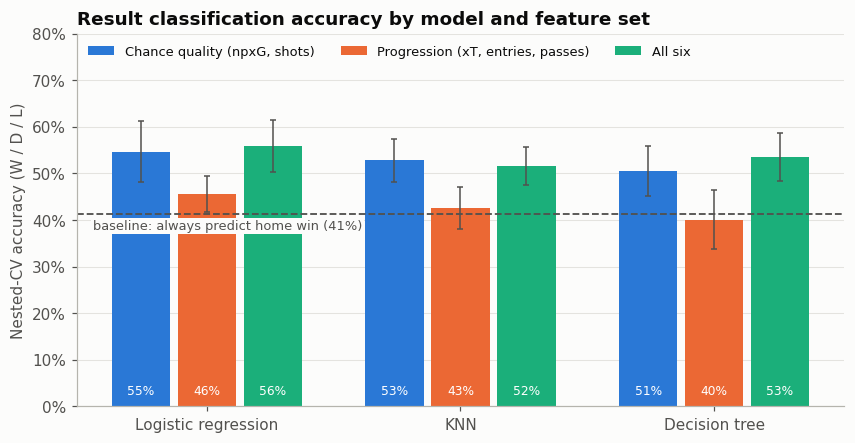

In [6]:
models_to_plot = ["Logistic regression", "KNN", "Decision tree"]
sets = list(FEATURE_SETS)
baseline = clf_results.loc[clf_results["model"] == "Majority class", "accuracy"].iloc[0]

fig, ax = plt.subplots(figsize=(9, 4.4))
width = 0.26
xs = np.arange(len(models_to_plot))
for i, s in enumerate(sets):
    vals = clf_results[(clf_results["features"] == s)].set_index("model").loc[models_to_plot]
    bars = ax.bar(xs + (i - 1) * width, vals["accuracy"], width=width - 0.03, color=SERIES[i], label=s,
                  yerr=vals["accuracy_sd"], error_kw={"ecolor": TEXT_SECONDARY, "elinewidth": 1, "capsize": 2})
    for b, v in zip(bars, vals["accuracy"]):
        ax.text(b.get_x() + b.get_width() / 2, 0.02, f"{v:.0%}", ha="center", va="bottom", fontsize=8, color="white")
ax.axhline(baseline, color=TEXT_SECONDARY, lw=1.2, ls="--")
ax.text(-0.45, baseline - 0.012, f"baseline: always predict home win ({baseline:.0%})",
        ha="left", va="top", fontsize=8.5, color=TEXT_SECONDARY,
        bbox={"facecolor": SURFACE, "edgecolor": "none", "pad": 1})
ax.set_xticks(xs, models_to_plot)
ax.set_ylim(0, 0.8)
ax.yaxis.set_major_formatter(lambda v, _: f"{v:.0%}")
ax.set_ylabel("Nested-CV accuracy (W / D / L)")
ax.set_title("Result classification accuracy by model and feature set")
ax.legend(loc="upper left", ncols=3, fontsize=8.5)
ax.grid(axis="x", visible=False)
save(fig, "match_outcome_accuracy")
plt.show()

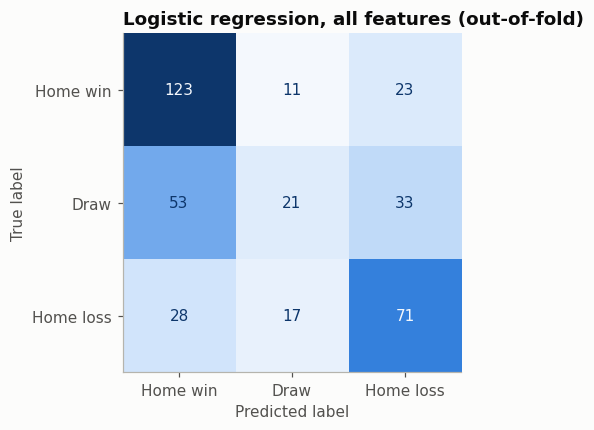

In [7]:
best_cols = FEATURE_SETS["All six"]
pred = cross_val_predict(classifiers["Logistic regression"], home[best_cols], y,
                         cv=StratifiedKFold(5, shuffle=True, random_state=RANDOM_STATE))
fig, ax = plt.subplots(figsize=(4.6, 4))
ConfusionMatrixDisplay.from_predictions(y, pred, labels=["W", "D", "L"],
                                        display_labels=["Home win", "Draw", "Home loss"],
                                        cmap=SEQUENTIAL, colorbar=False, ax=ax)
ax.grid(False)
ax.set_title("Logistic regression, all features (out-of-fold)")
save(fig, "match_outcome_confusion")
plt.show()

### What does a simple tree learn?

A depth-3 tree on all six features is fitted for interpretation only. It is not the tuned model.

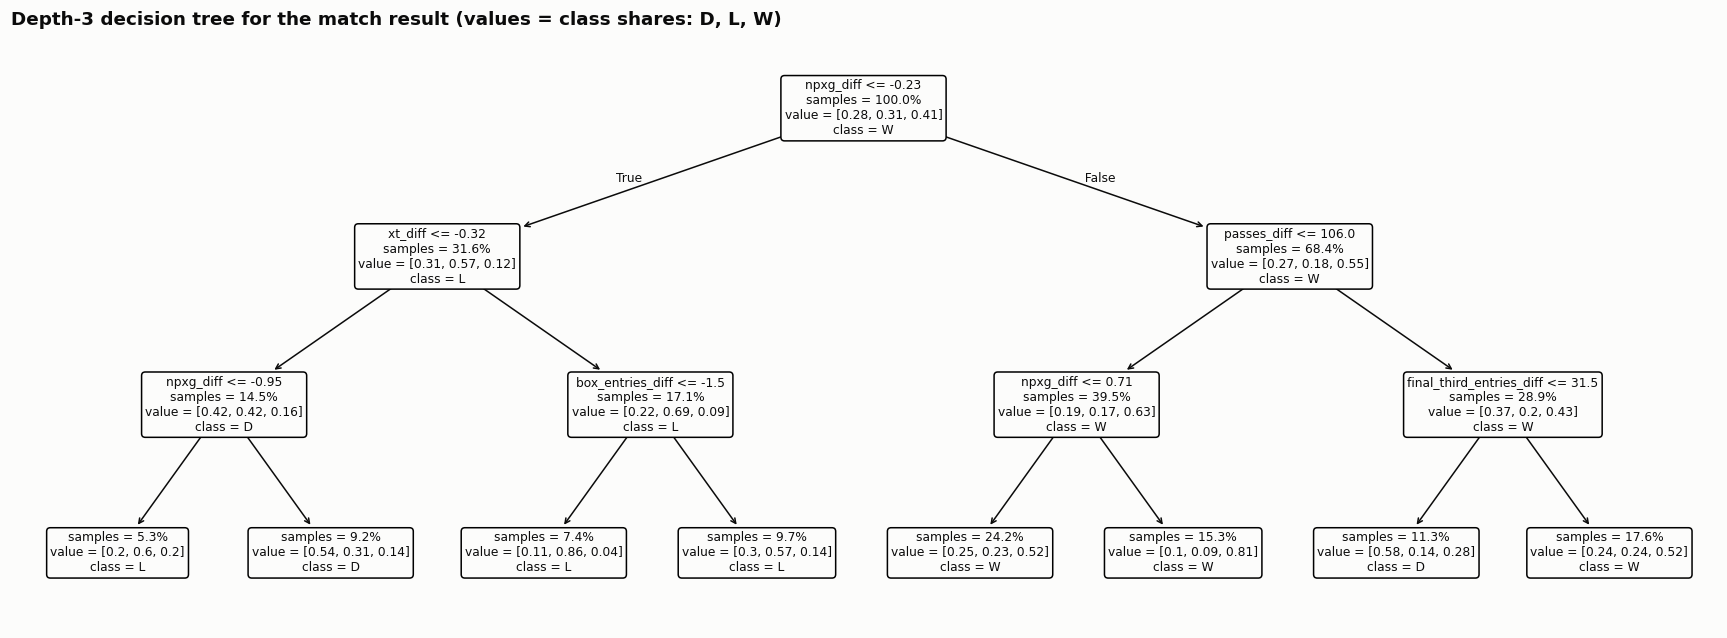

In [8]:
tree = DecisionTreeClassifier(max_depth=3, min_samples_leaf=15, random_state=RANDOM_STATE).fit(home[best_cols], y)
fig, ax = plt.subplots(figsize=(20, 7))
plot_tree(tree, feature_names=best_cols, class_names=list(tree.classes_), filled=False, impurity=False,
          proportion=True, rounded=True, precision=2, fontsize=8, ax=ax)
ax.set_title("Depth-3 decision tree for the match result (values = class shares: D, L, W)")
save(fig, "match_outcome_tree")
plt.show()

## Q3. Explaining a team's goals in a match

Linear regression of each team's goals in a match on its own attacking numbers. All 760 team-match rows are used, with **GroupKFold by match** so that both sides of a match always fall in the same fold.

In [9]:
groups = team_match["match_id"]
reg_sets = {
    "npxG": ["npxg"],
    "xT": ["xt"],
    "npxG + xT": ["npxg", "xt"],
    "npxG + xT + box entries + shots": ["npxg", "xt", "box_entries", "shots"],
}
rows = []
for name, cols in reg_sets.items():
    cv = cross_validate(LinearRegression(), team_match[cols], team_match["goals_for"], groups=groups,
                        cv=GroupKFold(5), scoring=["r2", "neg_mean_absolute_error"])
    rows.append({"features": name, "CV R²": cv["test_r2"].mean(), "CV MAE (goals)": -cv["test_neg_mean_absolute_error"].mean()})
reg_results = pd.DataFrame(rows).set_index("features")
reg_results

,CV R²,CV MAE (goals)
features,,
npxG,0.229,0.848
xT,0.019,0.958
npxG + xT,0.243,0.841
npxG + xT + box entries + shots,0.246,0.836


In [10]:
coef = LinearRegression().fit(team_match[["npxg", "xt"]], team_match["goals_for"])
print(f"goals ≈ {coef.intercept_:.2f} + {coef.coef_[0]:.2f}·npxG + {coef.coef_[1]:.2f}·xT")

goals ≈ 0.53 + 1.11·npxG + -0.47·xT


## Takeaways

1. **Underlying numbers tell you the result a bit over half the time.** The best model (logistic regression on all six differentials) classifies 56% of matches correctly in nested CV, against 41% for always predicting a home win. A single match is noisy: npxG explains only about 23% of the variance in a team's goals.
2. **Chance quality does almost all the work.** npxG and shot differentials alone reach 55%. Progression metrics alone (xT, box and final-third entries, passes) reach only 40 to 46%, barely above the baseline, and adding them to chance quality gains about 1 point, which is inside the fold-to-fold spread. The simpler logistic model matches or beats the tuned KNN and tree, which suggests the signal is close to linear.
3. **Draws are where every model fails.** Draws make up 28% of matches but are rarely predicted. A draw doesn't have a distinctive statistical profile, because it sits between the two clear-cut outcomes.
4. **Once npxG is known, xT has a *negative* coefficient for goals** (−0.47 per unit of xT). A plausible explanation, not tested here, is **game state**: teams that are behind push forward and pile up territory, while teams that are ahead sit deep, so territory partly reflects the scoreline rather than causing goals. Testing this would need possession-by-possession scoreline data.

**Limitations.** These models use within-match statistics, so they describe results rather than forecast them. One season of 380 matches makes the accuracy differences between models (1 to 3 points) statistically indistinguishable.